# Лабораторная 1. Иерархический кластерный анализ
Выполнил: Двиков Даниил Владиславович

Активируем библиотеки

In [101]:
import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

import os

Задаем рабочую папку

In [102]:
os.chdir("E:/анализ данных/1 lab")


In [103]:
df = pd.read_csv("Леденцы.dat", sep=";")

In [104]:
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [105]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [124]:
print(df.dtypes)
print('Все значения в данных:', np.unique(df.values))

V1     int64
V2     int64
V3     int64
V4     int64
V5     int64
V6     int64
V7     int64
V8     int64
V9     int64
V10    int64
V11    int64
dtype: object
Все значения в данных: [2 3 4 5]


Видим, что используется порядковая шкала от 2 до 5. Все 11 переменных измерены в одной и той же шкале с одинаковым диапазоном, поэтому стандартизация данных не нужна.

In [106]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

Построим дендрограммы для четырёх способов вычисления расстояния между кластерами: single, complete, average, ward. Выберем тот, где кластеры видны наиболее ясно. Для всех методов используем одну и ту же метрику, евклидово расстояние. Так сравнение получается честным: дендрограммы различаются только способом объединения кластеров

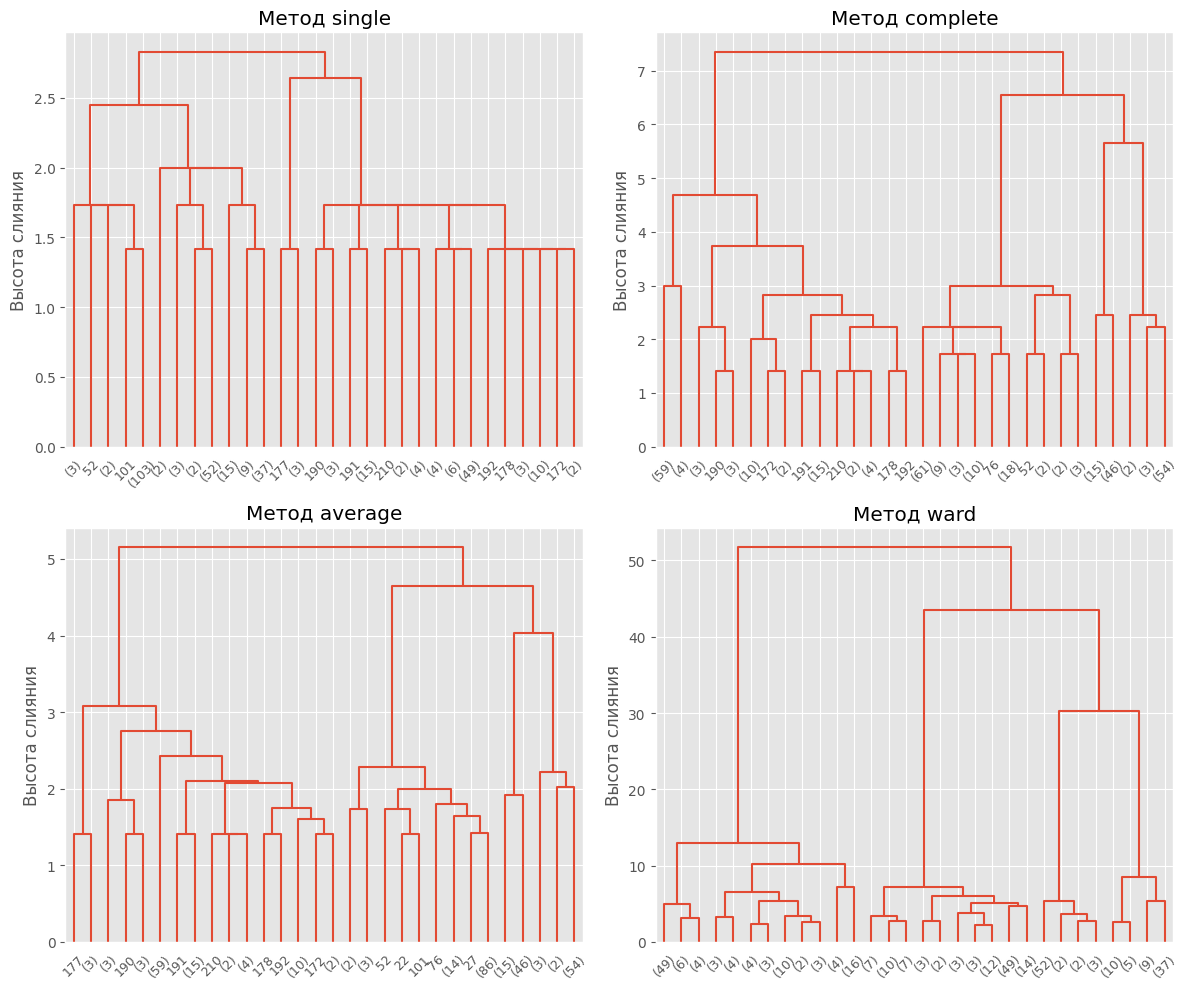

In [121]:
#  Сравниваем методы: сокращённые дендрограммы на одном рисунке
methods = ['single', 'complete', 'average', 'ward']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, method in enumerate(methods):
    link_m = linkage(df, method, 'euclidean')
    dendrogram(link_m,
               truncate_mode='lastp', # показываем только последние объединения 
               color_threshold=-1,
               leaf_rotation=45.,
               leaf_font_size=9,
               ax=axes[i])
    axes[i].set_title('Метод ' + method)
    axes[i].set_ylabel('Высота слияния')

plt.tight_layout()

Выводы по сравнению методов

- Single. Сильнее всего выделяется метод одиночной связи. Объекты у него присоединяются к кластерам по одному, многие объединения происходят на одной и той же высоте (около 1,4 и 1,7), и вместо отдельных групп получается цепочка. По такой дендрограмме нельзя определить число кластеров, поэтому этот метод не подходит.

- Complete, Average. У полной и средней связи четыре группы уже видно, но последние объединения происходят на близких высотах: у полной связи примерно 4,7, 5,7, 6,6 и 7,4, у средней 3,1, 4,0, 4,7 и 5,2. Резкого скачка высоты слияния нет, поэтому по этим дендрограммам трудно однозначно выбрать пороговое расстояние, а значит, и число кластеров.

- Ward. Самая наглядная дендрограмма у метода Уорда. Четыре группы формируются на высоте не больше 13, а между собой объединяются только на 30, 43 и 52. Разрыв между 13 и 30 хорошо заметен: если провести горизонтальную линию в этом промежутке, она пересечёт ровно четыре ветви.

Дальше работаем с методом Уорда, потому что на его дендрограмме граница между кластерами видна лучше всего. 

In [108]:
link = linkage(df, 'ward', 'euclidean')

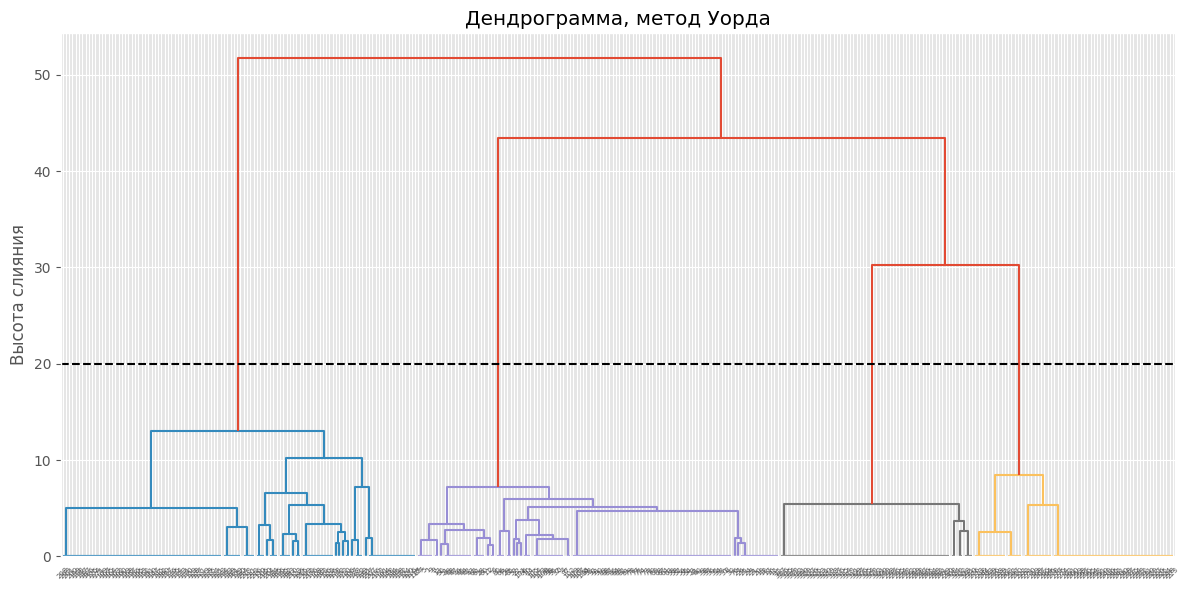

In [120]:
fig = plt.figure(figsize=(12, 6))
dn = dendrogram(link,
                color_threshold=20,
                leaf_rotation=45.)
plt.axhline(20, c='k', linestyle='dashed')
plt.title('Дендрограмма, метод Уорда')
plt.ylabel('Высота слияния')
plt.tight_layout()

Text(0.5, 1.0, 'Дендрограмма, последние 20 объединений')

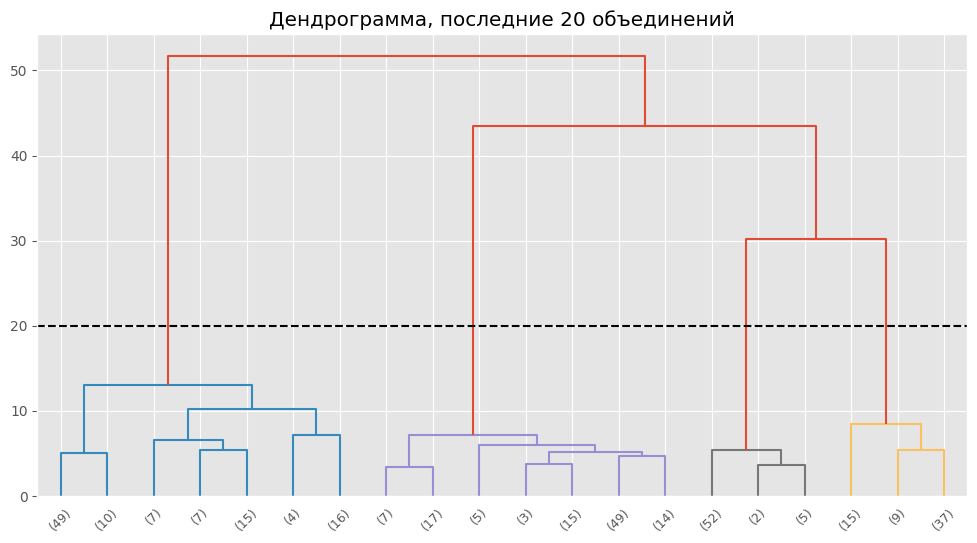

In [118]:
#  Сокращенная дендрограмма: последние 20 объединений
#  в скобках - число объектов в ветке
fig = plt.figure(figsize=(12, 6))
dn = dendrogram(link,
                truncate_mode='lastp', # очистка по оси x: хлопываем "кашу"
                p=20, #  оставляем только 20 верхних веток
                color_threshold=20,
                leaf_rotation=45.,
                leaf_font_size=9)
plt.axhline(20, c='k', linestyle='dashed')
plt.title('Дендрограмма, последние 20 объединений')

По дендограмме видно, что распределение выделяет 4 кластера

## Каменистая осыпь, метод локтя

Используем столбец link[:, 2] - расстояния между объединяемыми кластерами. Данных много, поэтому показываем только последние 15 объединений.

In [131]:
dist = link[:, 2]
dist_rev = dist[::-1]
dist_rev[:10]

array([51.70554708, 43.44161878, 30.21829021, 13.03013582, 10.21643334,
        8.49202664,  7.18679344,  7.17827943,  6.55149433,  5.97927803])

Text(0, 0.5, 'Расстояние')

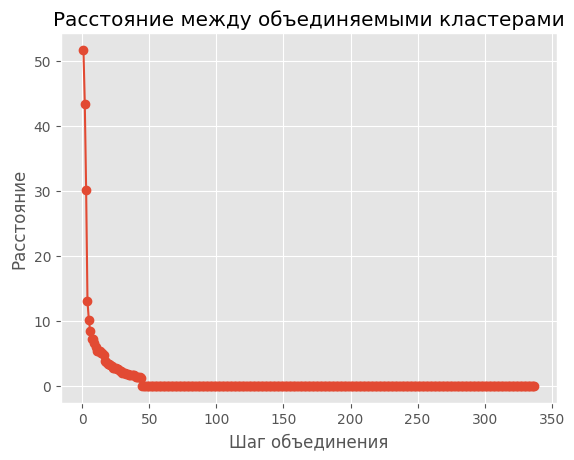

In [132]:
dist_rev = dist[::-1]
idxs = range(1, len(dist) + 1)
plt.plot(idxs, dist_rev, marker='o')
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')


Между 3-м и 4-м шагом с конца расстояние резко падает (30.2 $\to$ 13.0), дальше график выходит на горизонталь. Значит останавливаемся на 4 кластерах. На дендрограмме это тот же разрыв: разрез на высоте 20 пересекает ровно 4 ветви.

Вывод: число кластеров равно 4.


In [95]:
corr = df.corr()
corr.round(2)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
V1,1.00,0.90,0.90,0.86,-0.04,-0.04,-0.13,-0.22,-0.43,-0.42,-0.43
V2,0.90,1.00,0.97,0.92,-0.06,-0.05,-0.17,-0.24,-0.41,-0.41,-0.41
V3,0.90,0.97,1.00,0.93,-0.03,-0.02,-0.16,-0.23,-0.43,-0.42,-0.42
V4,0.86,0.92,0.93,1.00,0.05,0.05,-0.08,-0.15,-0.47,-0.46,-0.47
V5,-0.04,-0.06,-0.03,0.05,1.00,0.99,0.01,-0.11,-0.54,-0.52,-0.52
V6,-0.04,-0.05,-0.02,0.05,0.99,1.00,0.04,-0.09,-0.55,-0.53,-0.53
V7,-0.13,-0.17,-0.16,-0.08,0.01,0.04,1.00,0.94,-0.38,-0.37,-0.37
V8,-0.22,-0.24,-0.23,-0.15,-0.11,-0.09,0.94,1.00,-0.26,-0.26,-0.26
V9,-0.43,-0.41,-0.43,-0.47,-0.54,-0.55,-0.38,-0.26,1.00,0.97,0.96
V10,-0.42,-0.41,-0.42,-0.46,-0.52,-0.53,-0.37,-0.26,0.97,1.00,0.99


Text(0.5, 1.0, 'Корреляционная матрица')

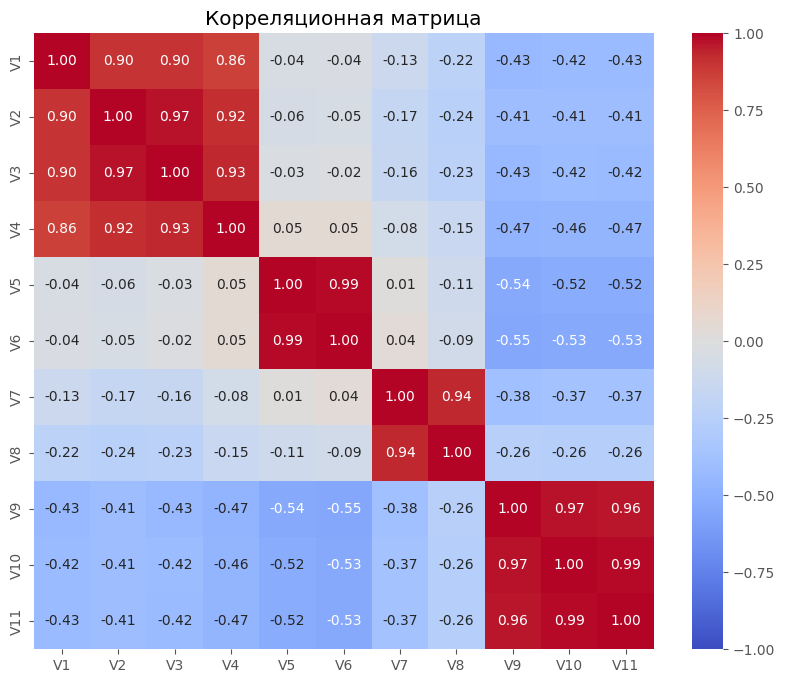

In [96]:
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляционная матрица')

Корреляционная матрица распадается на 4 блока сильно связанных высказываний:

V1–V4 (свежесть дыхания, уверенность)

V5–V6 (желание сладкого)

V7–V8 (концентрация, пауза)

V9–V11 (горло, нос, самочувствие)

Внутри блоков высказывания почти дублируют друг друга: если человек согласен с одним, он согласен и с остальными из того же блока. Между блоками слабая корреляция. Получается, что у респондентов, как правило, одна главная причина потребления леденцов.

In [97]:
df['cluster'] = fcluster(link, 4, criterion='maxclust')

In [98]:
sizes = df.groupby('cluster').size()
pd.DataFrame({'Человек': sizes,
              'Доля, %': (sizes / len(df) * 100).round(1)})

,Человек,"Доля, %"
cluster,,
1,108,32.0
2,110,32.5
3,59,17.5
4,61,18.0


In [99]:
means = df.groupby('cluster').mean().round(2)
means

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
1,2.82,2.83,2.77,2.62,2.61,2.58,2.75,2.92,4.95,4.81,4.86
2,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
3,3.00,2.97,2.97,2.92,2.92,2.95,4.92,4.92,3.00,3.00,3.00
4,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75


Средняя оценка по каждому блоку высказываний

In [100]:
blocks = {'Освежение (V1–V4)':    ['V1', 'V2', 'V3', 'V4'],
          'Сладкое (V5–V6)':      ['V5', 'V6'],
          'Концентрация (V7–V8)': ['V7', 'V8'],
          'Лечение (V9–V11)':     ['V9', 'V10', 'V11']}

pd.DataFrame({name: means[cols].mean(axis=1) for name, cols in blocks.items()}).round(2)

,Освежение (V1–V4),Сладкое (V5–V6),Концентрация (V7–V8),Лечение (V9–V11)
cluster,,,,
1,2.76,2.60,2.84,4.87
2,4.79,3.04,3.00,3.06
3,2.97,2.94,4.92,3.00
4,3.00,4.85,2.96,2.75


## Выводы:
Первый кластер (108 человек) едят леденцы, когда болеют. Они высоко оценили V9–V11: боль в горле, заложенный нос, плохое самочувствие. Остальные причины у них оценены даже ниже тройки, так что для них леденец скорее лекарство, чем сладость.

Во второй кластер (110 человек) попали те, кому важно свежее дыхание. У них высокие оценки по V1–V4: освежить дыхание и рот, убрать неприятный вкус, чувствовать себя увереннее при общении. Другие высказывания они оценили нейтрально.

Третий кластер (59 человек) едят леденцы, чтобы сосредоточиться или отвлечься на пару минут и подумать (V7 и V8 по 4,92). Скорее всего, это люди, которые много работают или учатся.

Четвёртый кластер (61 человек) – сладкоежки. Для них леденец просто заменяет конфеты, когда хочется чего-нибудь сладкого (V5 и V6 по 4,85). Лечебный эффект их почти не интересует (2,75).

В итоге получилось четыре понятных сегмента. Даже самый маленький из них составляет 17,5 % выборки, так что все группы достаточно крупные. Самые большие сегменты связаны с простудой и свежим дыханием, вместе это около двух третей респондентов, поэтому компании в первую очередь стоит ориентироваться на них.